In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import time
from IPython.display import clear_output

In [2]:
class doublegyre2d(object):
    """The Double Gyre vector field."""

    def __init__(self, a=0.1, eps=0.25, omega=np.pi/5):
        self.A = a
        self.EPS = eps
        self.OMEGA = omega

    # Samples the Double Gyre vector field
    def sample(self, x, y, t):
        u = -self.A * np.pi * np.sin(np.pi*(self.EPS*np.sin(self.OMEGA*t)*x*x + (1 - 2 * self.EPS*np.sin(self.OMEGA*t))*x))*np.cos(np.pi*y)
        v = self.A * np.pi*(2 * self.EPS*np.sin(self.OMEGA*t)*x - 2 * self.EPS*np.sin(self.OMEGA*t) + 1)* np.cos(np.pi*(self.EPS*np.sin(self.OMEGA*t)*x*x + (1 - 2 * self.EPS*np.sin(self.OMEGA*t))*x))*np.sin(np.pi*y)
        return u, v;

    # Samples the x-partial of the Double Gyre vector field
    def sample_dx(self, x, y, t):
        u = -self.A * np.pi*np.pi * (2 * self.EPS*np.sin(self.OMEGA*t)*x - 2 * self.EPS*np.sin(self.OMEGA*t) + 1)*np.cos(np.pi*(self.EPS*np.sin(self.OMEGA*t)*x*x + (1 - 2 * self.EPS*np.sin(self.OMEGA*t))*x))*np.cos(np.pi*y)
        v = 2 * self.A*self.EPS*np.pi* np.sin(self.OMEGA*t)*np.cos(np.pi*(self.EPS*np.sin(self.OMEGA*t)*x*x + (1 - 2 * self.EPS*np.sin(self.OMEGA*t))*x))*np.sin(np.pi*y) - self.A * np.pi*np.pi * (2 * self.EPS*np.sin(self.OMEGA*t)*x - 2 * self.EPS*np.sin(self.OMEGA*t) + 1) * (2 * self.EPS*np.sin(self.OMEGA*t)*x - 2 * self.EPS*np.sin(self.OMEGA*t) + 1) * np.sin(np.pi*(self.EPS*np.sin(self.OMEGA*t)*x*x + (1 - 2 * self.EPS*np.sin(self.OMEGA*t))*x))*np.sin(np.pi*y)
        return u, v;

    # Samples the y-partial of the Double Gyre vector field
    def sample_dy(self, x, y, t):
        u = self.A * np.pi*np.pi * np.sin(np.pi*(self.EPS*np.sin(self.OMEGA*t)*x*x + (1 - 2 * self.EPS*np.sin(self.OMEGA*t))*x))*np.sin(np.pi*y)
        v = self.A * np.pi*np.pi * (2 * self.EPS*np.sin(self.OMEGA*t)*x - 2 * self.EPS*np.sin(self.OMEGA*t) + 1)*np.cos(np.pi*(self.EPS*np.sin(self.OMEGA*t)*x*x + (1 - 2 * self.EPS*np.sin(self.OMEGA*t))*x))*np.cos(np.pi*y)
        return u, v;

    # Samples the t-partial of the Double Gyre vector field
    def sample_dt(self, x, y, t):
        u = -self.A * np.pi*np.pi * (self.EPS*self.OMEGA*np.cos(self.OMEGA*t)*x*x - 2 * self.EPS*self.OMEGA*np.cos(self.OMEGA*t)*x)*np.cos(np.pi*(self.EPS*np.sin(self.OMEGA*t)*x*x + (1 - 2 * self.EPS*np.sin(self.OMEGA*t))*x))*np.cos(np.pi*y)
        v = self.A * np.pi *	(2 * self.EPS*self.OMEGA*np.cos(self.OMEGA*t)*x - 2 * self.EPS*self.OMEGA*np.cos(self.OMEGA*t))*np.cos(np.pi*(self.EPS*np.sin(self.OMEGA*t)*x*x + (1 - 2 * self.EPS*np.sin(self.OMEGA*t))*x))*np.sin(np.pi*y) - self.A * np.pi*np.pi * (2 * self.EPS*np.sin(self.OMEGA*t)*x - 2 * self.EPS*np.sin(self.OMEGA*t) + 1)*(self.EPS*self.OMEGA*np.cos(self.OMEGA*t)*x*x - 2 * self.EPS*self.OMEGA*np.cos(self.OMEGA*t)*x) * np.sin(np.pi*(self.EPS*np.sin(self.OMEGA*t)*x*x + (1 - 2 * self.EPS*np.sin(self.OMEGA*t))*x))*np.sin(np.pi*y)
        return u, v;

In [3]:
def compute_animated_lic(u, v, noise, phase, length=16, step_size=0.008):
    """Calcula LIC con desplazamiento de fase para animar la dirección del flujo."""
    ny, nx = noise.shape
    y_grid, x_grid = np.mgrid[0:ny, 0:nx].astype(np.float64)
    
    mag = np.hypot(u, v) + 1e-12
    u_norm, v_norm = u / mag, v / mag
    
    u_px = u_norm * (nx / 2.0) * step_size
    v_px = v_norm * (ny / 1.0) * step_size

    # Kernel inicial en s = 0
    w0 = 0.5 * (1.0 + np.cos(phase))
    acc = noise * w0
    weight_sum = w0
    
    # Integrar hacia adelante (+1) y hacia atrás (-1) con onda viajera
    for direction in [1.0, -1.0]:
        cx, cy = x_grid.copy(), y_grid.copy()
        for step in range(1, length + 1):
            ix = np.clip(np.round(cx).astype(int), 0, nx - 1)
            iy = np.clip(np.round(cy).astype(int), 0, ny - 1)
            
            # Paso medio RK2
            mx = np.clip(np.round(cx + 0.5 * direction * u_px[iy, ix]).astype(int), 0, nx - 1)
            my = np.clip(np.round(cy + 0.5 * direction * v_px[iy, ix]).astype(int), 0, ny - 1)
            
            cx += direction * u_px[my, mx]
            cy += direction * v_px[my, mx]
            
            sx = np.clip(np.round(cx).astype(int), 0, nx - 1)
            sy = np.clip(np.round(cy).astype(int), 0, ny - 1)
            
            # Onda sinusoidal que viaja en dirección del flujo
            s = direction * step * 0.45
            # Ventana de Hanning para suavizar los extremos de la línea
            hanning = 0.5 * (1.0 + np.cos(np.pi * step / (length + 1)))
            weight = hanning * 0.5 * (1.0 + np.cos(s - phase))
            
            acc += noise[sy, sx] * weight
            weight_sum += weight

    lic = acc / (weight_sum + 1e-12)
    # Normalizar contraste del LIC
    lic = (lic - lic.min()) / (lic.max() - lic.min() + 1e-12)
    
    # Combinar textura LIC con la magnitud de velocidad real
    mag_norm = mag / (mag.max() + 1e-12)
    # Resaltar filamentos manteniendo visibilidad en zonas lentas
    combined = lic * (0.35 + 0.65 * np.sqrt(mag_norm))
    return combined

In [4]:
t0 = time.time()
dg = doublegyre2d(a=0.1, eps=0.35, omega=np.pi/5)
res_x, res_y = 40*4, 20*4
x = np.linspace(0.0, 2.0, res_x)
y = np.linspace(0.0, 1.0, res_y)
X, Y = np.meshgrid(x, y)

np.random.seed(42)
base_noise = np.random.rand(res_y, res_x)

t_max = 10.0
dt = 0.1
times = np.arange(0.0, t_max, dt)
num_frames = len(times)

frames_lic = np.empty((num_frames, res_y, res_x), dtype=np.float32)

for i, t_eval in enumerate(times):
    u, v = dg.sample(X, Y, t_eval)
    # La fase avanza rápido (t_eval * 8.0) para que se vea correr el fluido
    phase = -t_eval * 8.0
    frames_lic[i] = compute_animated_lic(u, v, base_noise, phase)

    if i % 2 == 0:
        clear_output(wait=True)
        #mag = np.sqrt(u**2 + v**2)
        #plt.pcolormesh(X, Y, mag, shading='gouraud')
        #plt.quiver(X, Y, u, v)
        plt.pcolormesh(X, Y, frames_lic[i])
        plt.title(f"Tiempo: {t_eval}")
        plt.show()
        plt.pause(0.01)

print(f"¡Listo en {time.time() - t0:.2f} segundos! ({num_frames} fotogramas)")

KeyboardInterrupt: 

In [90]:
t0 = time.time()
dg = doublegyre2d(a=0.1, eps=0.35, omega=np.pi/5)
res_x, res_y = 80, 40
x = np.linspace(0.0, 2.0, res_x)
y = np.linspace(0.0, 1.0, res_y)
X, Y = np.meshgrid(x, y)

T = 5.0
dt = 0.1
times = np.arange(0.0, T, dt)
Nt = len(times)

import torch
U = torch.zeros(Nt, res_y, res_x)
V = torch.zeros(Nt, res_y, res_x)

dU = torch.zeros_like(U)
dV = torch.zeros_like(V)

for k, t_eval in enumerate(times):
    u, v = dg.sample(X, Y, t_eval)
    u = torch.Tensor(u)
    v = torch.Tensor(v)
    U[k], V[k] = u, v

    du, dv = dg.sample_dt(X, Y, t_eval)
    du = torch.Tensor(du)
    dv = torch.Tensor(dv)
    dU[k], dV[k] = du, dv

A = 0.1 * torch.ones_like(U)
EPS = 0.35 * torch.ones_like(U)
OMEGA = np.pi / 5 * torch.ones_like(U)

data = torch.stack([U, V, A, EPS, OMEGA], dim=0)
targets = torch.stack([dU, dV], dim=0)

In [6]:
data.shape, targets.shape

(torch.Size([5, 100, 40, 80]), torch.Size([2, 100, 40, 80]))

In [97]:
from neuralop.models import FNO
import torch.nn as nn
import tqdm

model = FNO(
    n_modes=(32, 16),
    in_channels=5,   # u, v, A, eps, omega
    out_channels=2,  # du/dt, dv/dt
    hidden_channels=48,
    n_layers=3
)

optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
criterion = nn.MSELoss()

epochs = 50
model.train()
pbar = tqdm.tqdm(range(epochs))
min_loss = 1e6

Xin = data[:, :-1, :, :].permute(1, 0, 2, 3).to(device)  # [Nt-1, 5, H, W]
dS_real = targets[:, :-1, :, :].permute(1, 0, 2, 3).to(device)  # [Nt-1, 2, H, W]

for epoch in pbar:
    dS_preds = model(Xin)
    
    optimizer.zero_grad()
    loss = criterion(dS_preds, dS_real)
    loss.backward()
    optimizer.step()
    
    epoch_loss = loss.item()
    
    if epoch_loss < min_loss:
        torch.save(model.state_dict(), "model_weights.pt")
        min_loss = epoch_loss

    pbar.set_postfix(loss=f"{epoch_loss:.6f}", min_loss=f"{min_loss:.6f}")
    

 42%|████▏     | 21/50 [00:43<00:59,  2.06s/it, loss=0.003513, min_loss=0.003396]


KeyboardInterrupt: 

In [109]:
from neuralop.models import FNO
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import tqdm

# 1. Configurar el FNO
model = FNO(
    n_modes=(32, 16),
    in_channels=25,  # 22 canales de historia (u,v) + 3 parámetros (A, eps, omega)
    out_channels=2,  # du/dt, dv/dt
    hidden_channels=48,
    n_layers=3,
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
criterion = nn.MSELoss()

epochs = 100
min_loss = 1e6

# --- PASO CLAVE: CALCULAR ESTADÍSTICAS DE NORMALIZACIÓN ---
u_mean = data[0:2].mean()
u_std = data[0:2].std()

ds_mean = targets.mean()
ds_std = targets.std()

print(
    f"Estadísticas calculadas -> U_mean: {u_mean:.4f}, U_std: {u_std:.4f}"
)
print(f"Estadísticas targets -> dS_mean: {ds_mean:.4f}, dS_std: {ds_std:.4f}")

# --- CONSTRUCCIÓN DE LA HISTORIA CON NORMALIZACIÓN ---
num_delays = 10
Nt = data.shape[1]
H, W = data.shape[2], data.shape[3]

Xin_list = []
target_list = []

for k in range(num_delays, Nt - 1):
  # 1. Extraer historia de u y v -> [2, 11, H, W]
  vel_history = data[0:2, k - num_delays : k + 1, :, :]

  # Normalizar la historia de velocidades
  vel_history = (vel_history - u_mean) / (u_std + 1e-8)

  # Aplanar a canales -> [22, H, W]
  vel_history = vel_history.permute(1, 0, 2, 3).reshape(-1, H, W)

  # 2. Parámetros físicos en t (k) -> [3, H, W]
  params = data[2:5, k, :, :]

  # 3. Unir canales de entrada -> [25, H, W]
  sample_in = torch.cat([vel_history, params], dim=0)
  Xin_list.append(sample_in)

  # 4. Target real en k -> [2, H, W] y normalizar
  ds_target = targets[:, k, :, :]
  ds_target_norm = (ds_target - ds_mean) / (ds_std + 1e-8)
  target_list.append(ds_target_norm)

# Convertir a tensores globales
Xin_tensor = torch.stack(Xin_list, dim=0)
dS_real_tensor = torch.stack(target_list, dim=0)

# --- CREAR DATASET Y DATALOADER (EL SECRETO DEL SHUFFLE) ---
# Agrupamos las entradas y salidas para que viajen siempre juntas al mezclarse
dataset = TensorDataset(Xin_tensor, dS_real_tensor)

# batch_size igual al tamaño total procesará todo de golpe pero desordenado,
# o puedes usar mini-lotes (ej. batch_size=16 o 32) para mayor estocasticidad.
batch_size = len(
    dataset
)  # O pon un tamaño de batch fijo (ej. 16) si prefieres mini-batches
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

print(
    f"Dataset listo con {len(dataset)} muestras. ¡Listo para entrenar con shuffle!"
)

# --- BUCLE DE ENTRENAMIENTO CON SHUFFLE POR ÉPOCA ---
pbar = tqdm.tqdm(range(epochs))

for epoch in pbar:
  epoch_loss = 0.0
  model.train()

  # En cada época, el DataLoader desorganiza (shuffle) las muestras automáticamente
  for batch_Xin, batch_dS_real in dataloader:
    # Mover el lote actual a la GPU
    batch_Xin = batch_Xin.to(device)
    batch_dS_real = batch_dS_real.to(device)

    optimizer.zero_grad()

    # Predicción del lote
    dS_preds = model(batch_Xin)

    # Pérdida
    loss = criterion(dS_preds, batch_dS_real)
    loss.backward()

    optimizer.step()
    epoch_loss = loss.item()

  # Guardar el mejor modelo
  if epoch_loss < min_loss:
    torch.save(model.state_dict(), "model_weights_normalized.pt")
    min_loss = epoch_loss

  pbar.set_postfix(loss=f"{epoch_loss:.6f}", min_loss=f"{min_loss:.6f}")

Estadísticas calculadas -> U_mean: 0.0012, U_std: 0.1588
Estadísticas targets -> dS_mean: -0.0000, dS_std: 0.0588
Dataset listo con 39 muestras. ¡Listo para entrenar con shuffle!


100%|██████████| 100/100 [02:46<00:00,  1.66s/it, loss=0.000310, min_loss=0.000310]


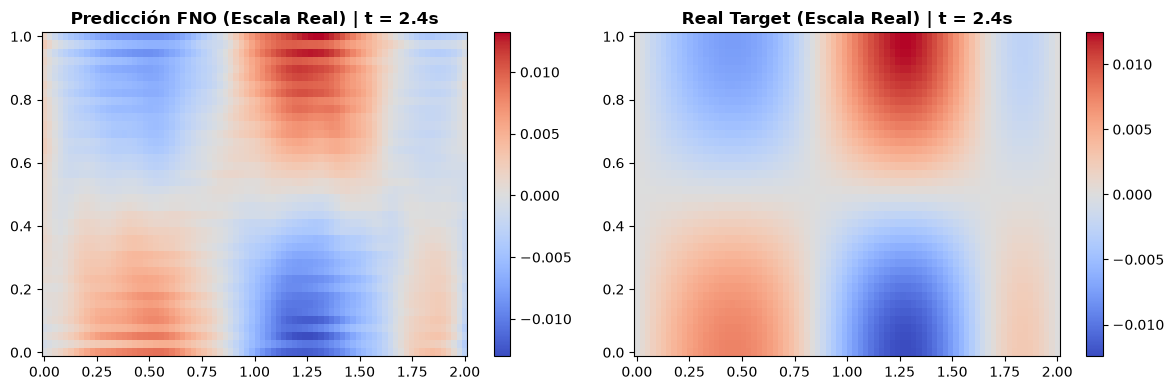

In [123]:
import matplotlib.pyplot as plt
import torch

# Asegúrate de cargar el modelo entrenado con normalización
model.load_state_dict(
    torch.load(
        "model_weights_normalized.pt", weights_only=False, map_location=device
    )
)
model.eval()

# Elegimos el instante de tiempo k (ej. k = 45)
k = 24
num_delays = 10
H, W = data.shape[2], data.shape[3]

with torch.no_grad():
  # 1. Construir la historia de velocidad (11 pasos: desde k - 10 hasta k) -> [2, 11, H, W]
  vel_history = data[0:2, k - num_delays : k + 1, :, :].to(device)

  # ¡OBLIGATORIO! Normalizar la entrada con las mismas estadísticas del entrenamiento
  vel_history = (vel_history - u_mean) / (u_std + 1e-8)

  # Aplanar a canales -> [22, H, W]
  vel_history = vel_history.permute(1, 0, 2, 3).reshape(-1, H, W)

  # 2. Parámetros físicos en el instante k -> [3, H, W]
  params = data[2:5, k, :, :].to(device)

  # 3. Concatenar para formar los 25 canales y añadir batch -> [1, 25, H, W]
  X_in = torch.cat([vel_history, params], dim=0).unsqueeze(0)

  # 4. Predicción del modelo (sale normalizada)
  pred_norm = model(X_in).squeeze(0)  # [2, H, W]

  # ¡OBLIGATORIO! Desnormalizar la predicción para llevarla a unidades físicas reales
  dU_pred = pred_norm[0] * ds_std + ds_mean
  dV_pred = pred_norm[1] * ds_std + ds_mean

  # 5. Targets reales correspondientes al instante k (estos ya están en su escala real)
  dU_real = targets[0, k, :, :].to(device)
  dV_real = targets[1, k, :, :].to(device)

  # --- 6. Graficar comparación ---
  fig, axes = plt.subplots(1, 2, figsize=(12, 4))

  im0 = axes[0].pcolormesh(
      X,
      Y,
      dU_pred.detach().cpu().numpy(),
      shading="auto",
      cmap="coolwarm",
      #vmin=-0.2,
      #vmax=0.2,
  )
  axes[0].set_title(
      f"Predicción FNO (Escala Real) | t = {k*dt:.1f}s", fontweight="bold"
  )
  fig.colorbar(im0, ax=axes[0])

  im1 = axes[1].pcolormesh(
      X,
      Y,
      dU_real.cpu().numpy(),
      shading="auto",
      cmap="coolwarm",
      #vmin=-0.2,
      #vmax=0.2,
  )
  axes[1].set_title(
      f"Real Target (Escala Real) | t = {k*dt:.1f}s", fontweight="bold"
  )
  fig.colorbar(im1, ax=axes[1])

  plt.tight_layout()
  plt.show()

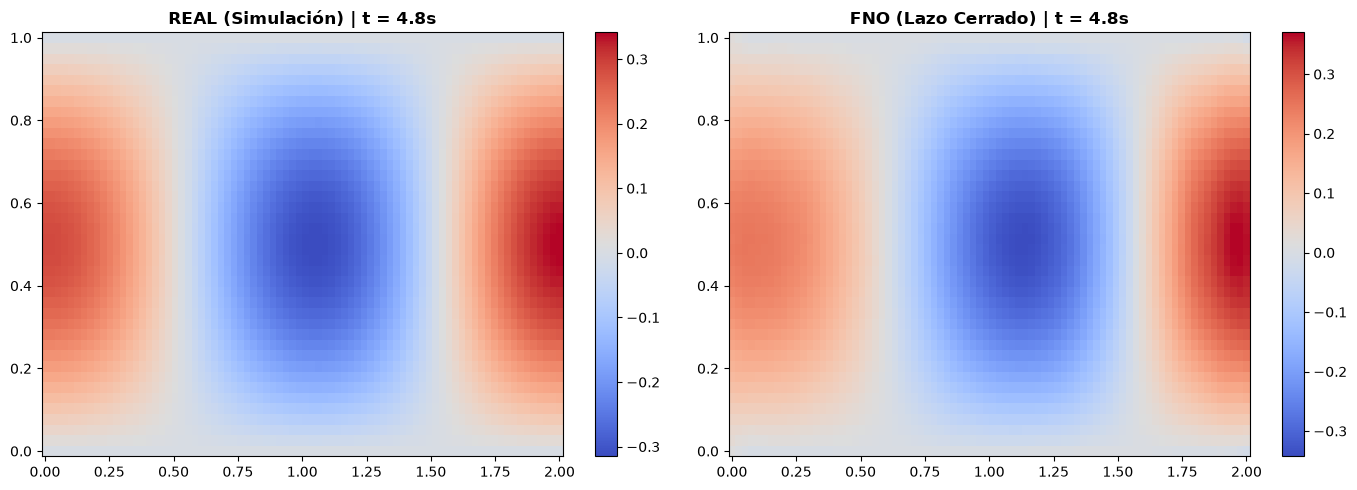

¡Animación finalizada en 24.79 segundos!


In [141]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import torch

model.eval()

# --- 1. CONFIGURACIÓN DEL ROLLOUT ---
num_delays = 10
# El rollout debe empezar en k = num_delays para tener historia válida
start_idx = num_delays
end_idx = Nt - 1

# Inicializamos un tensor para guardar las velocidades predichas en lazo cerrado
# Copiamos la historia real inicial para los primeros 10 pasos (hasta k = num_delays)
u_rollout = data[0].clone()  # [Nt, H, W]
v_rollout = data[1].clone()  # [Nt, H, W]

# --- 2. BUCLE AUTOREGRESIVO (LAZO CERRADO) ---
with torch.no_grad():
  for k in range(start_idx, end_idx):
    # A. Construir la historia actual (mezclando datos reales pasados y predicciones previas)
    # Desde (k - num_delays) hasta k
    vel_history_u = u_rollout[k - num_delays : k + 1]  # [11, H, W]
    vel_history_v = v_rollout[k - num_delays : k + 1]  # [11, H, W]

    # Apilar y normalizar la historia con las estadísticas del entrenamiento
    vel_history = torch.stack([vel_history_u, vel_history_v], dim=0)  # [2, 11, H, W]
    vel_history_norm = (vel_history - u_mean) / (u_std + 1e-8)
    vel_history_flat = vel_history_norm.permute(1, 0, 2, 3).reshape(-1, H, W)  # [22, H, W]

    # B. Parámetros físicos en el instante k -> [3, H, W]
    params = data[2:5, k, :, :].to(device)

    # C. Concatenar canales y añadir batch -> [1, 25, H, W]
    X_in = torch.cat([vel_history_flat, params], dim=0).unsqueeze(0).to(device)

    # D. Predicción del modelo (desnormalizando la salida)
    pred_norm = model(X_in).squeeze(0)  # [2, H, W]
    du_dt = pred_norm[0] * ds_std + ds_mean
    dv_dt = pred_norm[1] * ds_std + ds_mean

    # E. Avanzar un paso temporal con Euler: U_{t+1} = U_t + dt * (dU/dt)
    u_rollout[k + 1] = u_rollout[k] + dt * du_dt
    v_rollout[k + 1] = v_rollout[k] + dt * dv_dt

print("¡Rollout en lazo cerrado completado con éxito!")


import numpy as np
import time

t0 = time.time()

for i in range(start_idx, end_idx):
  t_eval = times[i]

  # Extraer campos reales vs rollout en el instante i
  # (aquí puedes graficar la magnitud de la velocidad o la componente u)
  u_real = data[0, i].cpu().numpy()
  u_pred = u_rollout[i].cpu().numpy()

  clear_output(wait=True)

  fig, axes = plt.subplots(1, 2, figsize=(14, 5))

  # Gráfica Real
  im0 = axes[0].pcolormesh(X, Y, u_real, shading="auto", cmap="coolwarm")#, vmin=-1.2, vmax=1.2)
  axes[0].set_title(f"REAL (Simulación) | t = {t_eval:.1f}s", fontweight="bold")
  fig.colorbar(im0, ax=axes[0])

  # Gráfica FNO (Lazo Cerrado)
  im1 = axes[1].pcolormesh(X, Y, u_pred, shading="auto", cmap="coolwarm")#, vmin=-1.2, vmax=1.2)
  axes[1].set_title(f"FNO (Lazo Cerrado) | t = {t_eval:.1f}s", fontweight="bold")
  fig.colorbar(im1, ax=axes[1])

  plt.tight_layout()
  plt.show()
  plt.pause(0.01)

print(f"¡Animación finalizada en {time.time() - t0:.2f} segundos!")

In [ ]:
# --- 4. ANIMACIÓN Y VISUALIZACIÓN ---
t0 = time.time()

H, W = data.shape[2], data.shape[3]  # Obtenemos las dimensiones espaciales reales de los tensores

# Redefinir base_noise para que coincida exactamente con H y W (ej. 40, 80)
np.random.seed(42)
base_noise = np.random.rand(H, W)

# Inicializar contenedores para los fotogramas LIC con las dimensiones correctas (Nt, H, W)
frames_lic1 = np.empty((Nt, H, W), dtype=np.float32)
frames_lic2 = np.empty((Nt, H, W), dtype=np.float32)

for i in range(start_idx, end_idx):
  t_eval = times[i]

  # Extraer campos reales vs rollout en el instante i
  u_real = data[0, i].cpu().numpy()
  v_real = data[1, i].cpu().numpy()
  u_pred = u_rollout[i].cpu().numpy()
  v_pred = v_rollout[i].cpu().numpy()

  # Fase para animar las líneas de corriente
  phase = -t_eval * 8.0
  frames_lic1[i] = compute_animated_lic(u_real, v_real, base_noise, phase)
  frames_lic2[i] = compute_animated_lic(u_pred, v_pred, base_noise, phase)

  clear_output(wait=True)

  fig, axes = plt.subplots(1, 2, figsize=(14, 5))

  # Gráfica Real (usamos cmap='gray' para texturas LIC óptimas)
  im0 = axes[0].pcolormesh(X, Y, frames_lic1[i], shading="auto", cmap="gray", vmin=0, vmax=1)
  axes[0].set_title(f"REAL (Simulación) | t = {t_eval:.1f}s", fontweight="bold")

  # Gráfica FNO (Lazo Cerrado)
  im1 = axes[1].pcolormesh(X, Y, frames_lic2[i], shading="auto", cmap="gray", vmin=0, vmax=1)
  axes[1].set_title(f"FNO (Lazo Cerrado) | t = {t_eval:.1f}s", fontweight="bold")

  plt.tight_layout()
  plt.show()
  plt.pause(0.01)

print(f"¡Animación finalizada en {time.time() - t0:.2f} segundos!")